GALLAPONT Thibault - MALLE Arnaud - MUEL Thomas

# Projet de NLP

*INSA Lyon 5A, basé sur le challenge CLEF EXIST 2024*

## Détection des tweets sexistes (EXIST 2024)

Le but est de décider si un tweet, en anglais ou en espagnol, est sexiste (YES) ou non (NO). C'est la tâche 1 du challenge EXIST 2024. Un tweet compte comme sexiste dès qu'il parle de sexisme, même pour le dénoncer.

Chaque tweet a été annoté par six personnes, et on a accès aux six réponses. On peut donc en tirer deux types d'étiquettes :

- **hard** : le vote majoritaire (au moins 4 « oui » sur 6). Les égalités 3 contre 3 sont écartées ;
- **soft** : la proportion de « oui » (par exemple 4/6 ≈ 0,67), qui garde la trace du désaccord.

On commence par des modèles simples (TF-IDF et modèles linéaires) pour avoir une référence, puis on fine-tune RoBERTa, le type de modèle utilisé par les meilleures équipes du challenge.

## 1. Chargement

In [1]:
%pip install -q numpy pandas scipy scikit-learn xgboost matplotlib seaborn jinja2 transformers tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import json
import re
import html
import importlib.util
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, vstack

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 160)

PALETTE = {"NO": "#4C72B0", "YES": "#C44E52"}
LANG_PALETTE = {"en": "#55A868", "es": "#DD8452"}

DATA_DIR = Path("data")
RANDOM_STATE = 42
RUN_ROBERTA = True   # partie 8, ignorée automatiquement si PyTorch n'est pas installé
USE_TRANSLATION = False   # partie 4 : True triple environ le temps d'exécution

Les fichiers sont des dictionnaires JSON {id: tweet}. On utilise le **train** pour entraîner et le **dev** comme jeu de test.

In [3]:
def load_exist(name):
    path = next(DATA_DIR.rglob(name))
    with open(path, encoding="utf-8") as f:
        return pd.DataFrame.from_dict(json.load(f), orient="index").reset_index(drop=True)


train_df = load_exist("EXIST2024_training.json")
dev_df = load_exist("EXIST2024_dev.json")

print(f"Train : {len(train_df)} tweets | Dev : {len(dev_df)} tweets")
train_df[["lang", "tweet", "labels_task1"]].head()

Train : 6920 tweets | Dev : 1038 tweets


,lang,tweet,labels_task1
0,es,"@TheChiflis Ignora al otro, es un capullo.El problema con este youtuber denuncia el acoso... cuando no afecta a la gente de izquierdas. Por ejemplo, en su v...","[YES, YES, NO, YES, YES, YES]"
1,es,@ultimonomada_ Si comicsgate se parece en algo a gamergate pues muy bien por el acoso. Y si se está haciendo un sabotaje porque hay personajes que no os gus...,"[NO, NO, NO, NO, YES, NO]"
2,es,"@Steven2897 Lee sobre Gamergate, y como eso ha cambiado la manera en la cual nos comunicamos en el internet. Los fanboys de Halo están tóxicos pero los fanb...","[NO, NO, NO, NO, NO, NO]"
3,es,"@Lunariita7 Un retraso social bastante lamentable, gamergate, trump, y aquí en españa pues lo que tenemos...","[NO, NO, YES, NO, YES, YES]"
4,es,@novadragon21 @icep4ck @TvDannyZ Entonces como así es el mercado lo mejor no es hacer algo para cambiarlo y seguir alimentando el machismo en los consumidor...,"[YES, NO, YES, NO, YES, YES]"


## 2. Exploration et étiquettes

Pour chaque tweet, on compte le nombre de « oui » (**n_yes**), on en déduit l'étiquette soft (**p_yes**) et l'étiquette hard (**hard**, vide en cas d'égalité).

In [4]:
def add_labels(df):
    df = df.copy()
    df["n_yes"] = df["labels_task1"].apply(lambda labels: sum(l == "YES" for l in labels))
    df["p_yes"] = df["n_yes"] / df["labels_task1"].str.len()
    df["hard"] = np.select([df["p_yes"] > 0.5, df["p_yes"] < 0.5], ["YES", "NO"], default=None)
    return df


train_df = add_labels(train_df)
dev_df = add_labels(dev_df)

pd.DataFrame({
    name: df["hard"].value_counts(dropna=False).rename(index={None: "Égalité (écartée)"})
    for name, df in [("Train", train_df), ("Dev", dev_df)]
})

,Train,Dev
hard,,
NO,3367,479
YES,2697,455
Égalité (écartée),856,104


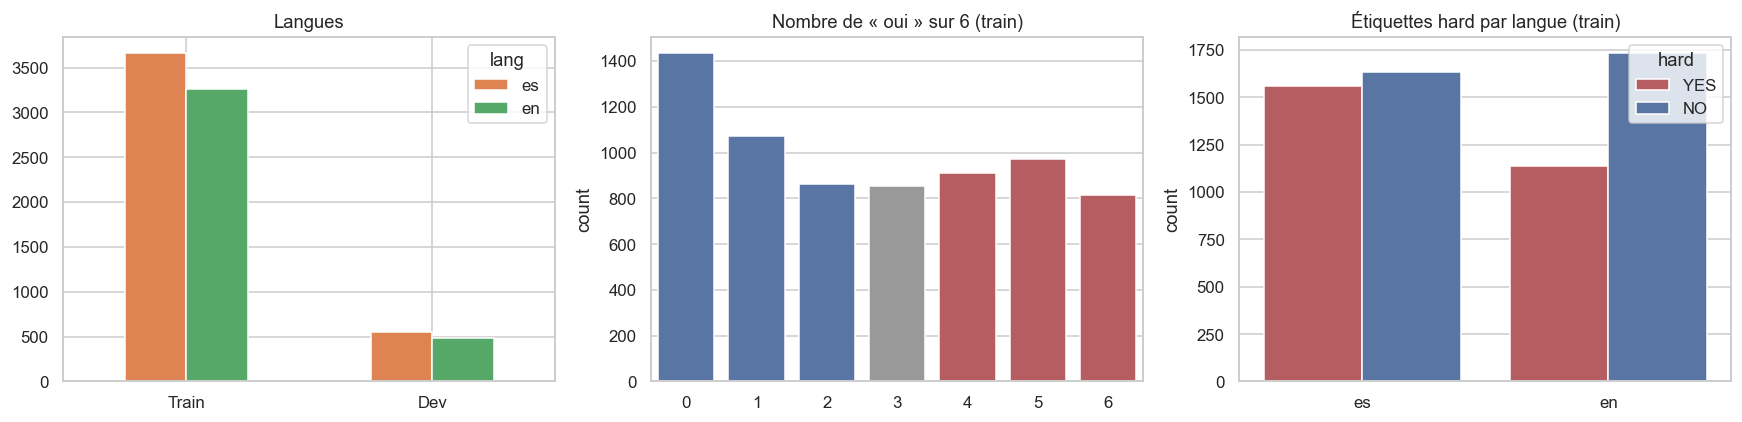

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

pd.concat([train_df["lang"].value_counts().rename("Train"), dev_df["lang"].value_counts().rename("Dev")], axis=1) \
    .T.plot.bar(ax=axes[0], color=[LANG_PALETTE["es"], LANG_PALETTE["en"]], rot=0)
axes[0].set_title("Langues")

colors = [PALETTE["NO"]] * 3 + ["#999999"] + [PALETTE["YES"]] * 3
sns.countplot(data=train_df, x="n_yes", order=range(7), palette=colors, hue="n_yes", legend=False, ax=axes[1])
axes[1].set_title("Nombre de « oui » sur 6 (train)")
axes[1].set_xlabel("")

sns.countplot(data=train_df.dropna(subset=["hard"]), x="lang", hue="hard", palette=PALETTE, ax=axes[2])
axes[2].set_title("Étiquettes hard par langue (train)")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

Trois observations :

- les deux langues sont à peu près aussi représentées. On entraîne donc **un seul modèle pour les deux**, ce qui double la quantité de données ;
- les classes sont assez équilibrées, avec un peu plus de NO en anglais ;
- l'unanimité est rare : beaucoup de tweets reçoivent 2, 3 ou 4 « oui ». Les 856 égalités (12 % du train) sont perdues avec les étiquettes hard, d'où l'intérêt des étiquettes soft (partie 7).

## 3. Nettoyage et mots indicateurs

On fait un nettoyage léger : les URLs deviennent « url », les mentions « @user » (pour ne pas apprendre des noms de comptes), et les hashtags sont découpés en mots (#IDoNotRenounce devient « i do not renounce »), car ils sont souvent très parlants. On ne retire pas les stopwords : il faudrait deux listes, et des mots comme *not* peuvent compter.

On garde deux versions : **clean**, en minuscules, pour TF-IDF, et **light**, avec les majuscules, pour RoBERTa, qui a été pré-entraîné sur du texte brut.

In [6]:
URL = re.compile(r"https?://\S+|www\.\S+")
MENTION = re.compile(r"@\w+")
HASHTAG = re.compile(r"#(\w+)")
CAMEL = re.compile(r"(?<=[a-záéíóúñ])(?=[A-ZÁÉÍÓÚÑ])")
REPEAT = re.compile(r"(\w)\1{2,}")


def clean_tweet(text, lowercase=True):
    text = html.unescape(text)
    text = URL.sub(" url ", text)
    text = MENTION.sub(" @user ", text)
    text = HASHTAG.sub(lambda m: " " + CAMEL.sub(" ", m.group(1)) + " ", text)
    text = REPEAT.sub(r"\1\1", text)          # « siiiii » devient « sii »
    if lowercase:
        text = text.lower()
    return " ".join(text.split())


for df in (train_df, dev_df):
    df["clean"] = df["tweet"].apply(clean_tweet)
    df["light"] = df["tweet"].apply(clean_tweet, lowercase=False)

train_df[["tweet", "clean"]].sample(3, random_state=RANDOM_STATE)

,tweet,clean
468,@AnelPerezM Pues.... realmente sabes cuándo alguien aumenta tu serotonina... porque ver una mujer atractiva pues si.... pero que realmente te enamore...lo s...,@user pues.... realmente sabes cuándo alguien aumenta tu serotonina... porque ver una mujer atractiva pues si.... pero que realmente te enamore...lo sientes...
1956,@giuli_cc:A confesión de parte relevo de prueba.Claramente el ex Minedu CUENCA sostiene q el enfoque de género es lo más alejado a lo binario.¿No q el enfoq...,@user :a confesión de parte relevo de prueba.claramente el ex minedu cuenca sostiene q el enfoque de género es lo más alejado a lo binario.¿no q el enfoque ...
800,Lourenzá organiza obradoiros de coeducación para o alumnado do CEIP Juan Rey https://t.co/72CR8KNChl,lourenzá organiza obradoiros de coeducación para o alumnado do ceip juan rey url


### Mots indicateurs de sexisme

On ajoute au preprocessing une courte liste de mots, un tableau par langue, dont l'emploi signale presque toujours un tweet sexiste : des insultes visant spécifiquement les femmes (*whore*, *zorra*, *marimacho*), des clichés (*dumb blonde*, *rubia*, *sumisa*) ou le mot *feminazi*.

Pour les choisir, on est parti des mots les plus associés à la classe **YES** dans le **train**, puis on n'a gardé que ceux qui sont sexistes par leur sens et qui apparaissent dans au moins 80 % des cas dans des tweets sexistes. Des insultes comme *bitch* ou *puta* ont été écartées : elles sont aussi très utilisées dans des tweets non sexistes (insultes générales, citations, dénonciations). Le dev n'a pas servi à construire la liste.

Quand un tweet contient l'un de ces mots, on ajoute à la fin le marqueur « lex_sexiste ». TF-IDF voit déjà chaque mot séparément, mais ces mots sont rares (une vingtaine d'apparitions chacun) et leurs poids sont donc peu fiables. Le marqueur les regroupe : le modèle apprend un seul poids, plus solide, pour tous ces mots. On ne l'utilise que pour TF-IDF : RoBERTa connaît déjà le sens de ces mots, et le marqueur serait pour lui un mot inconnu.

In [7]:
MOTS_SEXISTES_EN = ["feminazi", "feminazis", "whore", "whores", "hoe", "bimbo", "prostitute", "dumb", "blonde",
                    "spank", "cook", "sandwich", "skirt", "trophy", "tits", "carousel"]
MOTS_SEXISTES_ES = ["feminazi", "feminazis", "zorra", "zorras", "golfa", "marimacho", "frígida", "frigida", "tonta",
                    "rubia", "sumisa", "obediente", "azotar"]

MOTS_SEXISTES = {"en": set(MOTS_SEXISTES_EN), "es": set(MOTS_SEXISTES_ES)}
WORD = re.compile(r"[a-záéíóúñü]+")


def add_lexicon_marker(text, lang):
    # Ajoute « lex_sexiste » à la fin du tweet s'il contient un mot de la liste de sa langue
    return text + " lex_sexiste" if MOTS_SEXISTES[lang] & set(WORD.findall(text)) else text


for df in (train_df, dev_df):
    df["clean_lex"] = [add_lexicon_marker(t, l) for t, l in zip(df["clean"], df["lang"])]

# Vérification sur le train
train_lex = train_df[train_df["hard"].notna()].assign(marque=lambda d: d["clean_lex"].str.endswith("lex_sexiste"))
pd.DataFrame({
    lang: {"Tweets avec un mot de la liste": g["marque"].sum(),
           "Part de YES parmi eux": (g.loc[g["marque"], "hard"] == "YES").mean(),
           "Part des tweets YES couverts": g.loc[g["hard"] == "YES", "marque"].mean()}
    for lang, g in train_lex.groupby("lang")
}).T.style.format({"Tweets avec un mot de la liste": "{:.0f}", "Part de YES parmi eux": "{:.0%}",
                   "Part des tweets YES couverts": "{:.0%}"})

,Tweets avec un mot de la liste,Part de YES parmi eux,Part des tweets YES couverts
en,227,93%,18%
es,199,95%,12%


La liste est très fiable : 93 à 95 % des tweets qui contiennent un de ces mots sont sexistes. Mais elle ne couvre que 12 à 18 % des tweets sexistes, car beaucoup ne contiennent aucune insulte ni aucun cliché évident. C'est donc un indice pour le modèle, pas une règle de décision.

## 4. Augmentation par traduction

Cette partie est **désactivée par défaut** (USE_TRANSLATION = False dans la partie 1), car elle triple environ le temps d'exécution. Dans nos essais, elle n'a pas amélioré les résultats : aucun gain pour TF-IDF, -1,4 point de F1 pour RoBERTa hard et +0,4 pour RoBERTa soft. Le modèle étant déjà multilingue, une copie traduite lui apprend peu de choses nouvelles et ajoute des erreurs de traduction.

On a environ 3 300 tweets en anglais et 3 700 en espagnol. Pour avoir deux fois plus de données d'entraînement dans les deux langues, on **traduit tout l'espagnol en anglais et tout l'anglais en espagnol**, en gardant les annotations de chaque tweet : un tweet sexiste en espagnol donne aussi un tweet sexiste en anglais. C'est une technique utilisée par l'équipe gagnante du challenge. Les traductions servent à entraîner les mêmes modèles que d'habitude, avec plus d'exemples : on ne crée pas un modèle par langue.

On utilise les modèles de traduction **MarianMT** d'Helsinki-NLP ([opus-mt-en-es](https://huggingface.co/Helsinki-NLP/opus-mt-en-es) et [opus-mt-es-en](https://huggingface.co/Helsinki-NLP/opus-mt-es-en)). Ce sont de petits modèles spécialisés chacun dans une paire de langues : ils sont gratuits, tournent en local et traduisent les 7 000 tweets en une dizaine de minutes sur GPU. Un grand modèle de langue traduirait peut-être mieux l'argot, mais il serait bien plus lent ou payant.

Le résultat est enregistré dans un nouveau fichier, **EXIST2024_training_2.json**, au même format que le training : il contient les tweets originaux et leurs traductions, soit deux fois plus de tweets. Si le fichier existe déjà, on le recharge directement au lieu de tout retraduire.

On ne traduit que le **train**, jamais le dev : sinon, on évaluerait le modèle sur des tweets qu'il aurait vus dans l'autre langue.

In [ ]:
TRAIN2_NAME = "EXIST2024_training_2.json"
MT_MODELS = {"en": "Helsinki-NLP/opus-mt-en-es", "es": "Helsinki-NLP/opus-mt-es-en"}
TARGET_LANG = {"en": "es", "es": "en"}


def translate(texts, model_name, batch_size=32):
    import torch
    from tqdm.auto import tqdm
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device).eval()
    if device.type == "cuda":
        model = model.half()

    order = np.argsort([len(t) for t in texts])   # textes de longueur proche dans un même batch : plus rapide
    out = [None] * len(texts)
    for start in tqdm(range(0, len(texts), batch_size), desc=model_name.split("/")[-1]):
        idx = order[start:start + batch_size]
        enc = tok([texts[i] for i in idx], return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
        with torch.no_grad():
            generated = model.generate(**enc, num_beams=4, max_new_tokens=256)
        for i, t in zip(idx, tok.batch_decode(generated, skip_special_tokens=True)):
            out[i] = t
    return out



if USE_TRANSLATION:
    warnings.warn("Traduction activée : le temps d'exécution est environ triplé "
                  "(traduction au premier lancement, puis deux RoBERTa de plus entraînés sur deux fois plus de tweets).")
    if not any(DATA_DIR.rglob(TRAIN2_NAME)):
        original = json.loads(next(DATA_DIR.rglob("EXIST2024_training.json")).read_text(encoding="utf-8"))
        train2 = dict(original)
        for lang, model_name in MT_MODELS.items():
            sub = train_df[train_df["lang"] == lang]
            for tweet_id, translation in zip(sub["id_EXIST"], translate(list(sub["light"]), model_name)):
                entry = dict(original[tweet_id], id_EXIST=f"{tweet_id}_tr", lang=TARGET_LANG[lang],
                             tweet=translation, translated_from=tweet_id)
                train2[entry["id_EXIST"]] = entry
        (DATA_DIR / TRAIN2_NAME).write_text(json.dumps(train2, ensure_ascii=False, indent=1), encoding="utf-8")

    train2_df = add_labels(load_exist(TRAIN2_NAME))
    print(f"{TRAIN2_NAME} : {len(train2_df)} tweets ({len(train_df)} originaux + {train2_df['translated_from'].notna().sum()} traduits)")

    # Tweets traduits, remis dans le même ordre que train_df pour pouvoir réutiliser les mêmes masques
    aug_df = (train2_df[train2_df["translated_from"].notna()]
              .set_index("translated_from").loc[train_df["id_EXIST"]].reset_index(drop=True))
    aug_df["light"] = aug_df["tweet"].apply(clean_tweet, lowercase=False)
    aug_df["clean"] = aug_df["tweet"].apply(clean_tweet)
    aug_df["clean_lex"] = [add_lexicon_marker(t, l) for t, l in zip(aug_df["clean"], aug_df["lang"])]

    display(pd.DataFrame({"Original": train_df["light"], "Traduction": aug_df["light"]}).sample(4, random_state=RANDOM_STATE))
else:
    print("Traduction désactivée (USE_TRANSLATION = False dans la partie 1).")

Quand on active la traduction, on voit que les traductions gardent globalement le sens, mais ne sont pas parfaites : certaines phrases sont traduites mot à mot (« A confesión de parte relevo de prueba » devient « A confession of part proof relay »), et quelques tweets ne sont même pas en espagnol (le troisième exemple est en galicien). Ces erreurs ajoutent un peu de bruit dans les données.

## 5. Modèles TF-IDF

TF-IDF représente chaque tweet par les mots qu'il contient, pondérés selon leur rareté. On compare deux variantes :

- **mots** : mots seuls et paires de mots ;
- **mots + caractères** : on ajoute des morceaux de 2 à 5 lettres, plus robustes aux fautes, à l'argot et aux variantes (*feminazi*, *feminazis*), et qui fonctionnent dans les deux langues.

On compare plusieurs familles de modèles, chacune pour une raison précise :

- une **baseline** qui répond toujours la classe majoritaire, pour savoir à partir de quand un modèle apprend vraiment quelque chose ;
- trois **modèles linéaires**, qui sont en général les plus efficaces sur du TF-IDF, car ils gèrent bien des dizaines de milliers de variables creuses :
  - la **régression logistique** donne des probabilités (utiles pour la partie 7), et ses coefficients se lisent facilement ;
  - le **SVM linéaire** est le modèle de référence classique pour la classification de textes ;
  - le **Ridge Classifier**, une régression linéaire régularisée, très rapide ;
- **Naive Bayes** (variante Complement, adaptée au texte), le modèle le plus simple et le plus rapide, souvent utilisé comme point de comparaison ;
- deux modèles à base d'arbres, **Random Forest** et **XGBoost**, pour vérifier si des modèles non linéaires apportent quelque chose. Comme ils sont lents sur des vecteurs aussi grands, on ne les entraîne que sur la représentation par mots.

La métrique principale est le **F1 de la classe YES**, celle qu'utilise EXIST.

In [9]:
train_hard = train_df["hard"].notna().to_numpy()
dev_hard = dev_df["hard"].notna().to_numpy()
y_train = (train_df.loc[train_hard, "hard"] == "YES").astype(int).to_numpy()
y_dev = (dev_df.loc[dev_hard, "hard"] == "YES").astype(int).to_numpy()
CLASS_NAMES = ["NO", "YES"]

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=150_000, sublinear_tf=True)

# Vectoriseurs appris sur tout le train (y compris les égalités, utilisées en partie 7)
Xw_train, Xw_dev = word_vec.fit_transform(train_df["clean"]), word_vec.transform(dev_df["clean"])
Xc_train, Xc_dev = char_vec.fit_transform(train_df["clean"]), char_vec.transform(dev_df["clean"])

representations = {
    "Mots": (Xw_train, Xw_dev),
    "Mots + caractères": (hstack([Xw_train, Xc_train]).tocsr(), hstack([Xw_dev, Xc_dev]).tocsr()),
}

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Baseline (classe majoritaire)": lambda: DummyClassifier(strategy="most_frequent"),
    "Régression logistique": lambda: LogisticRegression(C=4, max_iter=3000, class_weight="balanced"),
    "SVM linéaire": lambda: LinearSVC(C=0.5, class_weight="balanced"),
    "Ridge Classifier": lambda: RidgeClassifier(alpha=1.0, class_weight="balanced"),
    "Naive Bayes": lambda: ComplementNB(alpha=0.3),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": lambda: XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, scale_pos_weight=pos_weight,
                                     tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
}
TREE_MODELS = {"Random Forest", "XGBoost"}   # trop lents sur « mots + caractères »


def evaluate(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Précision (YES)": precision_score(y_true, y_pred, zero_division=0),
        "Rappel (YES)": recall_score(y_true, y_pred, zero_division=0),
        "F1 (YES)": f1_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


trained_models, results = {}, []
for rep_name, (Xtr, Xte) in representations.items():
    for model_name, create_model in models.items():
        if model_name in TREE_MODELS and rep_name != "Mots":
            continue
        print(f"{rep_name} : {model_name}")
        model = create_model().fit(Xtr[train_hard], y_train)
        trained_models[(rep_name, model_name)] = model
        results.append({"Représentation": rep_name, "Modèle": model_name,
                        **evaluate(y_dev, model.predict(Xte[dev_hard]))})

metric_cols = list(evaluate([0, 1], [0, 1]))
results_df = pd.DataFrame(results).sort_values("F1 (YES)", ascending=False).reset_index(drop=True)
results_df.style.format({c: "{:.3f}" for c in metric_cols}) \
    .background_gradient(cmap="Reds", subset=["F1 (YES)", "Macro F1"]).hide(axis="index")

Mots : Baseline (classe majoritaire)
Mots : Régression logistique
Mots : SVM linéaire
Mots : Ridge Classifier
Mots : Naive Bayes
Mots : Random Forest
Mots : XGBoost
Mots + caractères : Baseline (classe majoritaire)
Mots + caractères : Régression logistique
Mots + caractères : SVM linéaire
Mots + caractères : Ridge Classifier
Mots + caractères : Naive Bayes


Représentation,Modèle,Accuracy,Précision (YES),Rappel (YES),F1 (YES),Macro F1
Mots + caractères,Régression logistique,0.792,0.803,0.760,0.781,0.792
Mots + caractères,SVM linéaire,0.786,0.794,0.756,0.775,0.785
Mots + caractères,Ridge Classifier,0.784,0.796,0.747,0.771,0.783
Mots,SVM linéaire,0.775,0.787,0.738,0.762,0.774
Mots,Ridge Classifier,0.771,0.784,0.732,0.757,0.770
Mots,Régression logistique,0.772,0.789,0.725,0.756,0.771
Mots,Naive Bayes,0.741,0.729,0.745,0.737,0.741
Mots,XGBoost,0.752,0.785,0.675,0.726,0.749
Mots + caractères,Naive Bayes,0.718,0.723,0.684,0.703,0.718
Mots,Random Forest,0.741,0.816,0.604,0.694,0.735


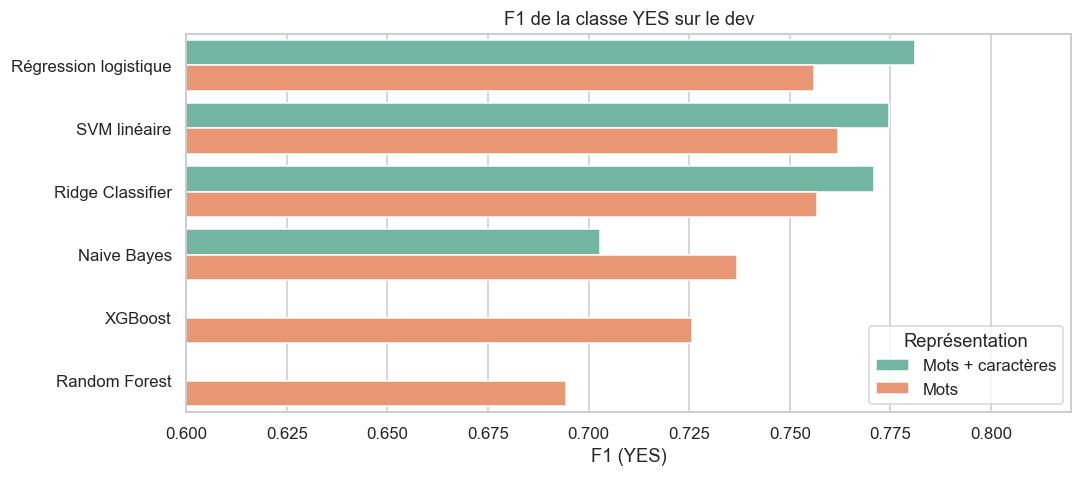

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=results_df[~results_df["Modèle"].str.startswith("Baseline")],
            y="Modèle", x="F1 (YES)", hue="Représentation", palette="Set2", ax=ax)
ax.set_xlim(0.6, 0.82)
ax.set_title("F1 de la classe YES sur le dev")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

La baseline a un F1 nul, puisqu'elle ne prédit jamais **YES** : tous les autres modèles apprennent donc quelque chose. Les trois modèles linéaires sont en tête et très proches les uns des autres, autour de **0,78 de F1** avec les caractères. L'ajout des caractères leur fait gagner entre 1 et 2,5 points. Naive Bayes et les modèles à base d'arbres restent nettement derrière : sur du TF-IDF, la non-linéarité des arbres n'apporte rien et coûte beaucoup en temps de calcul. On garde la régression logistique pour la suite, parce qu'elle donne des probabilités.

À noter : le meilleur modèle est choisi sur le dev, qui sert aussi à l'évaluer. Ce score est donc légèrement optimiste.

### Effet des mots indicateurs (et de la traduction)

On reprend le meilleur modèle (régression logistique, mots + caractères) et on compare la version de base avec celle qui utilise les mots indicateurs. Si la traduction est activée, on ajoute les versions entraînées avec les tweets traduits.

In [ ]:
def tfidf_variant(frames, col):
    """Régression logistique (mots + caractères) entraînée sur un ou plusieurs DataFrames de train."""
    word_v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
    char_v = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=150_000, sublinear_tf=True)
    fit_texts = pd.concat([f[col] for f in frames])
    word_v.fit(fit_texts)
    char_v.fit(fit_texts)
    vectorize = lambda texts: hstack([word_v.transform(texts), char_v.transform(texts)]).tocsr()

    X = vectorize(pd.concat([f.loc[train_hard, col] for f in frames]))
    model = LogisticRegression(C=4, max_iter=3000, class_weight="balanced").fit(X, np.tile(y_train, len(frames)))
    return model.predict(vectorize(dev_df.loc[dev_hard, col]))


variants = {
    "Base": ([train_df], "clean"),
    "+ mots indicateurs": ([train_df], "clean_lex"),
}
if USE_TRANSLATION:
    variants["+ traduction"] = ([train_df, aug_df], "clean")
    variants["+ traduction + mots indicateurs"] = ([train_df, aug_df], "clean_lex")
ablation = pd.DataFrame({name: evaluate(y_dev, tfidf_variant(*args)) for name, args in variants.items()}).T
ablation.style.format("{:.3f}").background_gradient(cmap="Reds", subset=["F1 (YES)", "Macro F1"])

Les mots indicateurs n'améliorent pas TF-IDF (0,778 contre 0,781, un écart trop petit pour être significatif). Ce n'est pas surprenant : TF-IDF voit déjà chacun de ces mots séparément, et ils ne concernent qu'une petite partie des tweets sexistes. Pour la suite de l'analyse, on garde donc le modèle de base.

## 6. Analyse des erreurs

In [12]:
def report_table(y_true, y_pred, title):
    """Rapport de classification sous forme de tableau."""
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    accuracy = report.pop("accuracy")
    table = (pd.DataFrame(report).T
             .rename(index={"macro avg": "Moyenne macro", "weighted avg": "Moyenne pondérée"},
                     columns={"precision": "Précision", "recall": "Rappel", "f1-score": "F1", "support": "Effectif"})
             .astype({"Effectif": int}))
    return (table.style
            .format({"Précision": "{:.3f}", "Rappel": "{:.3f}", "F1": "{:.3f}", "Effectif": "{:d}"})
            .background_gradient(cmap="Reds", subset=(CLASS_NAMES, ["Précision", "Rappel", "F1"]), vmin=0.5, vmax=1)
            .set_caption(f"{title} | accuracy = {accuracy:.3f}")
            .set_table_styles([
                {"selector": "caption", "props": "caption-side: top; font-size: 1.1em; font-weight: bold; padding-bottom: 8px;"},
                {"selector": "th, td", "props": "text-align: center; padding: 4px 12px;"},
                {"selector": "tbody tr:nth-child(3)", "props": "border-top: 2px solid #999;"},
            ]))


def scores_by_lang(y_pred):
    langs = dev_df.loc[dev_hard, "lang"].to_numpy()
    return pd.DataFrame({l: evaluate(y_dev[langs == l], y_pred[langs == l]) for l in sorted(set(langs))}).T


best_rep, best_name = "Mots + caractères", "Régression logistique"
y_pred_best = trained_models[(best_rep, best_name)].predict(representations[best_rep][1][dev_hard])

display(report_table(y_dev, y_pred_best, f"{best_name} ({best_rep})"))
display(scores_by_lang(y_pred_best).style.format("{:.3f}"))

,Précision,Rappel,F1,Effectif
NO,0.783,0.823,0.802,479
YES,0.803,0.760,0.781,455
Moyenne macro,0.793,0.791,0.792,934
Moyenne pondérée,0.793,0.792,0.792,934


,Accuracy,Précision (YES),Rappel (YES),F1 (YES),Macro F1
en,0.809,0.815,0.727,0.768,0.803
es,0.778,0.795,0.785,0.790,0.777


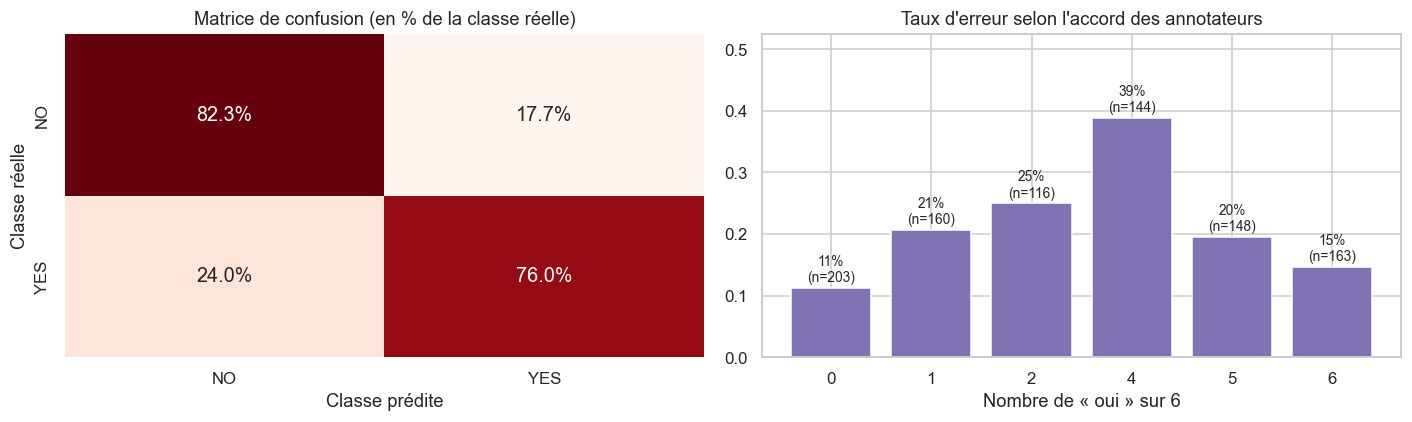

In [13]:
cm = confusion_matrix(y_dev, y_pred_best)
dev_eval = dev_df.loc[dev_hard].assign(erreur=y_dev != y_pred_best)
err = dev_eval.groupby("n_yes")["erreur"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".1%", cmap="Reds", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], annot_kws={"size": 13})
axes[0].set_xlabel("Classe prédite")
axes[0].set_ylabel("Classe réelle")
axes[0].set_title("Matrice de confusion (en % de la classe réelle)")

bars = axes[1].bar(err.index.astype(str), err["mean"], color="#8172B3")
for bar, (rate, n) in zip(bars, err.itertuples(index=False)):
    axes[1].text(bar.get_x() + bar.get_width() / 2, rate + 0.01, f"{rate:.0%}\n(n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0, err["mean"].max() * 1.35)
axes[1].set_xlabel("Nombre de « oui » sur 6")
axes[1].set_title("Taux d'erreur selon l'accord des annotateurs")
plt.tight_layout()
plt.show()

Le modèle se trompe sur 11 à 15 % des tweets où tout le monde est d'accord, mais sur près de 40 % de ceux qui n'ont reçu que 4 « oui » sur 6. Une bonne partie des erreurs porte donc sur des cas où les humains eux-mêmes hésitent.

Pour comprendre ce que le modèle a appris, on regarde les mots qui pèsent le plus dans la régression logistique (version « mots », plus lisible) :

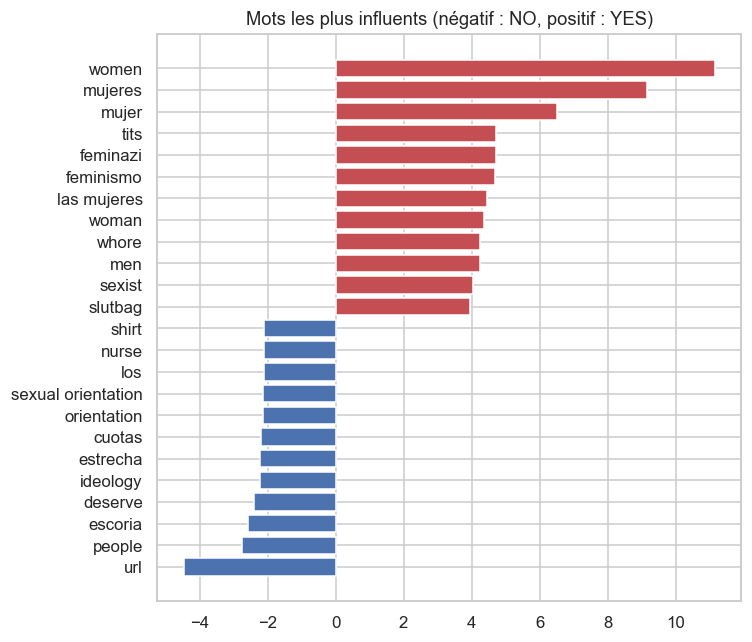

In [14]:
coefs = trained_models[("Mots", "Régression logistique")].coef_.ravel()
vocab = np.array(word_vec.get_feature_names_out())
idx = np.r_[np.argsort(coefs)[:12], np.argsort(coefs)[-12:]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(vocab[idx], coefs[idx], color=[PALETTE["NO"]] * 12 + [PALETTE["YES"]] * 12)
ax.set_title("Mots les plus influents (négatif : NO, positif : YES)")
plt.tight_layout()
plt.show()

Côté **YES**, on trouve surtout *women*, *mujeres*, des insultes et le vocabulaire du féminisme. C'est logique, mais cela montre la limite de TF-IDF : le modèle réagit à la présence de certains mots, sans comprendre ce qui est dit. Un tweet qui *dénonce* le sexisme utilise souvent les mêmes mots qu'un tweet sexiste. C'est précisément ce que RoBERTa devrait mieux gérer.

## 7. Étiquettes soft

Plutôt que d'apprendre « ce tweet est sexiste », on apprend « 4 personnes sur 6 le trouvent sexiste ». Cela permet d'utiliser les tweets à égalité et devrait donner des probabilités plus réalistes sur les cas ambigus.

scikit-learn n'accepte pas directement des cibles entre 0 et 1, mais on peut contourner le problème : chaque tweet est dupliqué, une fois étiqueté **YES** avec un poids **p_yes**, une fois **NO** avec un poids 1 - p_yes. La régression logistique minimise alors exactement la cross-entropy avec la proportion d'annotateurs.

Pour comparer, on regarde le F1 et la **cross-entropy** entre la probabilité prédite et **p_yes** (plus elle est basse, plus le modèle reproduit fidèlement l'avis des annotateurs).

In [15]:
Xs_train, Xs_dev = representations["Mots + caractères"]
p_train, p_dev = train_df["p_yes"].to_numpy(), dev_df["p_yes"].to_numpy()

w = np.r_[p_train, 1 - p_train]
keep = w > 0
soft_lr = LogisticRegression(C=4, max_iter=3000).fit(
    vstack([Xs_train, Xs_train]).tocsr()[keep], np.r_[np.ones(len(p_train)), np.zeros(len(p_train))][keep],
    sample_weight=w[keep])
hard_lr = trained_models[("Mots + caractères", "Régression logistique")]


def soft_cross_entropy(p_true, p_pred, eps=1e-7):
    p_pred = np.clip(p_pred, eps, 1 - eps)
    return -np.mean(p_true * np.log(p_pred) + (1 - p_true) * np.log(1 - p_pred))


def compare_row(name, proba):
    y_hat = (proba[dev_hard] >= 0.5).astype(int)
    return {"Modèle": name, "F1 (YES)": f1_score(y_dev, y_hat),
            "Cross-entropy": soft_cross_entropy(p_dev, proba), "proba": proba}


soft_df = pd.DataFrame([
    compare_row("TF-IDF, étiquettes hard", hard_lr.predict_proba(Xs_dev)[:, 1]),
    compare_row("TF-IDF, étiquettes soft", soft_lr.predict_proba(Xs_dev)[:, 1]),
]).set_index("Modèle")
soft_df.drop(columns="proba").style.format("{:.3f}")

,F1 (YES),Cross-entropy
Modèle,,
"TF-IDF, étiquettes hard",0.781,0.614
"TF-IDF, étiquettes soft",0.775,0.571


Le F1 ne bouge presque pas, mais la cross-entropy baisse nettement : le modèle soft est moins catégorique sur les tweets ambigus, et ses probabilités collent mieux à l'avis des annotateurs. On verra que l'effet est encore plus net avec RoBERTa.

## 8. RoBERTa

Dans l'article de synthèse d'EXIST 2024, presque toutes les meilleures équipes fine-tunent un modèle de la famille RoBERTa. Contrairement à TF-IDF, RoBERTa lit la phrase entière et représente chaque mot dans son contexte. Il peut donc, en principe, distinguer « les femmes ne savent pas conduire » de « j'en ai marre qu'on dise que les femmes ne savent pas conduire ».

On utilise [cardiffnlp/twitter-xlm-roberta-base](https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base), pour deux raisons :

- c'est un **XLM-RoBERTa**, la version multilingue de RoBERTa, donc un seul modèle suffit pour l'anglais et l'espagnol ;
- il a été ré-entraîné sur environ 200 millions de **tweets**, donc il connaît déjà l'argot, les hashtags et les emojis.

Le fine-tuning consiste à ajouter une couche de classification au-dessus du modèle, puis à tout ré-entraîner quelques époques sur nos tweets. On entraîne **un seul modèle, qui traite les deux langues**, de deux façons : avec les étiquettes hard, puis avec les étiquettes soft. Si la traduction est activée, on ajoute deux versions entraînées avec les tweets traduits, soit quatre au total. Ce sont toujours des versions du même modèle bilingue, pas un modèle par langue. On met 10 % du train de côté pour choisir la meilleure époque sans toucher au dev.

Compter une dizaine de minutes sur un GPU de portable pour les deux modèles (environ trois fois plus avec la traduction), plusieurs heures sur CPU.

In [16]:
if RUN_ROBERTA and not (importlib.util.find_spec("torch") and importlib.util.find_spec("transformers")):
    print("PyTorch ou transformers n'est pas installé : partie ignorée.")
    RUN_ROBERTA = False

if RUN_ROBERTA:
    import torch
    import torch.nn.functional as F
    from tqdm.auto import tqdm
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    from transformers.utils import logging as hf_logging

    hf_logging.set_verbosity_error()

    MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base"
    MAX_LEN, BATCH_SIZE, EPOCHS, LR = 128, 16, 3, 2e-5

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = device.type == "cuda"   # demi-précision sur GPU : plus rapide, moins de mémoire
    print("Calcul sur :", torch.cuda.get_device_name(0) if use_amp else "CPU")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

c:\Users\thiba\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Calcul sur : NVIDIA GeForce RTX 3070 Laptop GPU


On écrit la boucle d'entraînement à la main plutôt que d'utiliser le Trainer de Hugging Face : on voit ce qui se passe, et on peut facilement entraîner sur des cibles soft. La perte est la cross-entropy entre la sortie du modèle et [1 - p, p], où *p* vaut 0 ou 1 en hard et la proportion de « oui » en soft.

In [17]:
def iter_batches(texts, targets, batch_size, shuffle, rng=None):
    order = rng.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        enc = tokenizer([texts[i] for i in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        yield {k: v.to(device) for k, v in enc.items()}, torch.tensor(targets[idx], dtype=torch.float, device=device)


def predict_proba_roberta(model, texts):
    model.eval()
    probas = []
    with torch.no_grad():
        for enc, _ in iter_batches(texts, np.zeros(len(texts)), 64, shuffle=False):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(**enc).logits
            probas.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(probas)


def train_roberta(train_texts, train_targets, val_texts, val_p):
    """Fine-tune le modèle et garde l'époque avec la plus faible cross-entropy de validation."""
    torch.manual_seed(RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    n_batches = int(np.ceil(len(train_texts) / BATCH_SIZE))

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * EPOCHS * n_batches), EPOCHS * n_batches)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    history, best_loss, best_state = [], np.inf, None
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for enc, p in tqdm(iter_batches(train_texts, train_targets, BATCH_SIZE, True, rng),
                           total=n_batches, desc=f"Époque {epoch}/{EPOCHS}"):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(**enc).logits
            loss = F.cross_entropy(logits.float(), torch.stack([1 - p, p], dim=1))

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())

        val_loss = soft_cross_entropy(val_p, predict_proba_roberta(model, val_texts))
        history.append({"Époque": epoch, "Perte train": np.mean(losses), "Cross-entropy validation": val_loss})
        print(f"  perte train = {np.mean(losses):.4f} | cross-entropy validation = {val_loss:.4f}")
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

In [ ]:
if RUN_ROBERTA:
    is_val = np.random.default_rng(RANDOM_STATE).random(len(train_df)) < 0.10
    texts = train_df["light"].to_numpy()
    hard_targets = (train_df["hard"] == "YES").astype(float).to_numpy()
    val_texts, val_p = list(texts[is_val]), p_train[is_val]

    hard_mask = ~is_val & train_hard   # en hard, les égalités sont retirées du train, comme pour TF-IDF
    soft_mask = ~is_val
    setups = {   # (textes d'entraînement, cibles)
        "RoBERTa, hard": (texts[hard_mask], hard_targets[hard_mask]),
        "RoBERTa, soft": (texts[soft_mask], p_train[soft_mask]),
    }
    if USE_TRANSLATION:   # les traductions des tweets de validation sont exclues avec les mêmes masques
        texts_tr = aug_df["light"].to_numpy()
        setups["RoBERTa, hard + traduction"] = (np.r_[texts[hard_mask], texts_tr[hard_mask]], np.tile(hard_targets[hard_mask], 2))
        setups["RoBERTa, soft + traduction"] = (np.r_[texts[soft_mask], texts_tr[soft_mask]], np.tile(p_train[soft_mask], 2))

    roberta_histories, roberta_rows = {}, []
    for name, (train_texts, targets) in setups.items():
        print(f"\n{name} ({len(train_texts)} tweets)")
        model, roberta_histories[name] = train_roberta(list(train_texts), targets, val_texts, val_p)
        roberta_rows.append(compare_row(name, predict_proba_roberta(model, list(dev_df["light"]))))
        del model
        torch.cuda.empty_cache()

    soft_df = pd.concat([soft_df.drop(index=list(setups), errors="ignore"),
                         pd.DataFrame(roberta_rows).set_index("Modèle")])

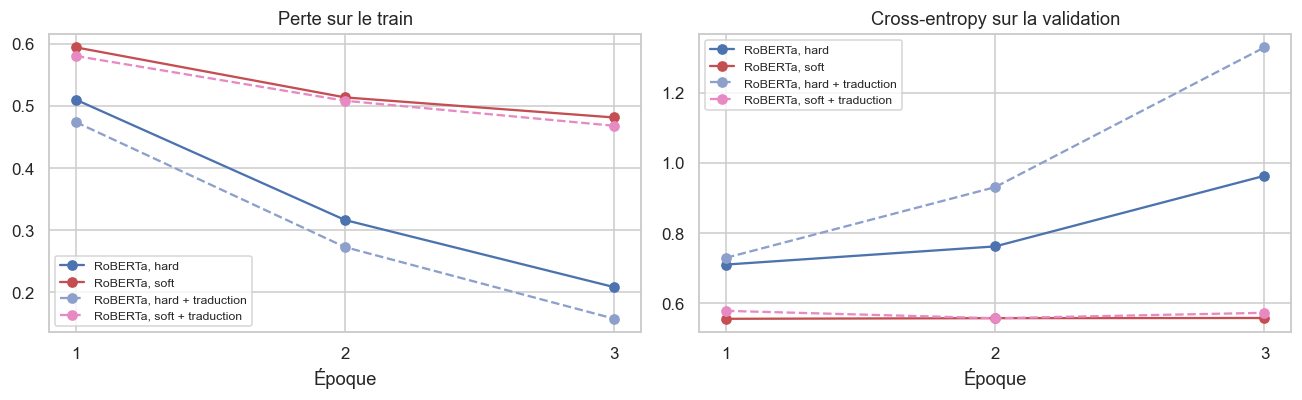

In [19]:

if RUN_ROBERTA:
    colors = dict(zip(setups, ["#4C72B0", "#C44E52", "#8DA0CB", "#E78AC3"]))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
    for name, h in roberta_histories.items():
        style = "o--" if "traduction" in name else "o-"
        axes[0].plot(h["Époque"], h["Perte train"], style, color=colors[name], label=name)
        axes[1].plot(h["Époque"], h["Cross-entropy validation"], style, color=colors[name], label=name)
    axes[0].set_title("Perte sur le train")
    axes[1].set_title("Cross-entropy sur la validation")
    for ax in axes:
        ax.set_xlabel("Époque")
        ax.set_xticks(range(1, EPOCHS + 1))
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


Avec les étiquettes hard, la cross-entropy de validation remonte dès la deuxième époque alors que la perte d'entraînement continue de baisser : le modèle devient trop sûr de lui, même sur les tweets ambigus. C'est du sur-apprentissage, d'où l'intérêt de garder la meilleure époque. Avec les étiquettes soft, les courbes restent presque plates : le modèle ne peut pas être plus catégorique que les annotateurs.

### Comparaison finale

,F1 (YES),Cross-entropy
Modèle,,
"TF-IDF, étiquettes hard",0.781,0.614
"TF-IDF, étiquettes soft",0.775,0.571
"RoBERTa, hard",0.845,0.641
"RoBERTa, soft",0.834,0.533
"RoBERTa, hard + traduction",0.831,0.656
"RoBERTa, soft + traduction",0.838,0.531


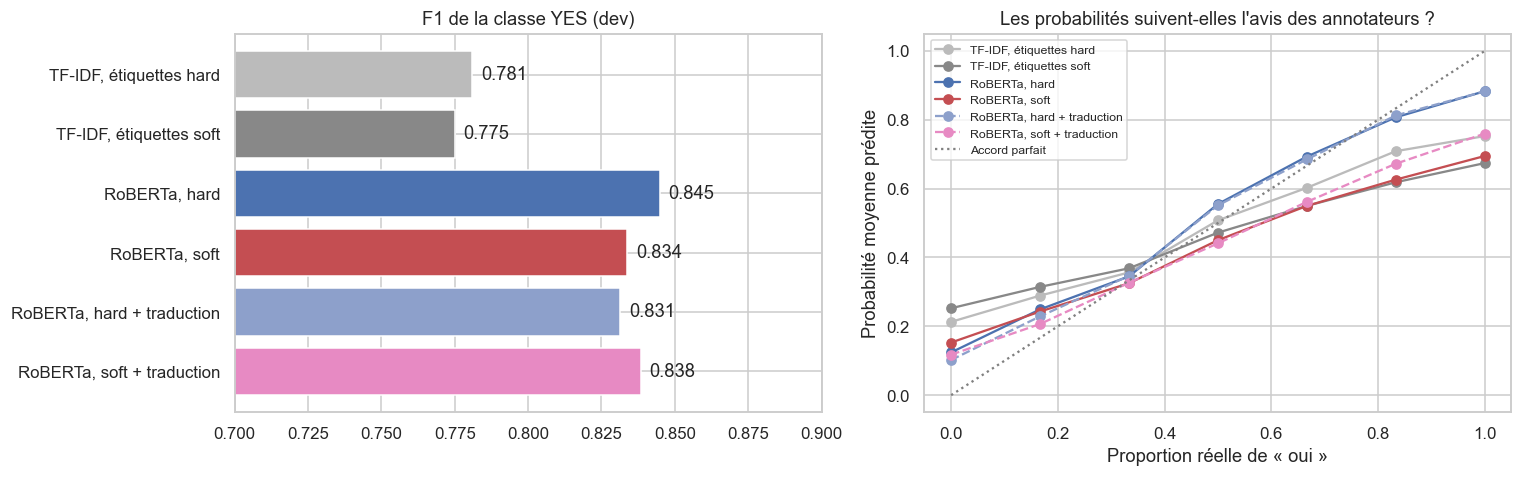

In [20]:

if RUN_ROBERTA:
    display(soft_df.drop(columns="proba").style.format("{:.3f}")
            .highlight_max(subset=["F1 (YES)"], color="#f4cccc")
            .highlight_min(subset=["Cross-entropy"], color="#f4cccc"))

    palette = ["#bbbbbb", "#888888", "#4C72B0", "#C44E52", "#8DA0CB", "#E78AC3"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    f1s = soft_df["F1 (YES)"]
    axes[0].barh(f1s.index, f1s.values, color=palette[:len(f1s)])
    for i, v in enumerate(f1s.values):
        axes[0].text(v + 0.003, i, f"{v:.3f}", va="center")
    axes[0].set_xlim(0.7, 0.9)
    axes[0].invert_yaxis()
    axes[0].set_title("F1 de la classe YES (dev)")

    for name, color in zip(soft_df.index, palette):
        curve = pd.Series(soft_df.loc[name, "proba"]).groupby(p_dev).mean()
        axes[1].plot(curve.index, curve.values, "o--" if "traduction" in name else "o-", color=color, label=name)
    axes[1].plot([0, 1], [0, 1], ":", color="grey", label="Accord parfait")
    axes[1].set_xlabel("Proportion réelle de « oui »")
    axes[1].set_ylabel("Probabilité moyenne prédite")
    axes[1].set_title("Les probabilités suivent-elles l'avis des annotateurs ?")
    axes[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


In [21]:
if RUN_ROBERTA:
    best_roberta = soft_df.loc[list(setups), "F1 (YES)"].idxmax()
    y_hat = (soft_df.loc[best_roberta, "proba"][dev_hard] >= 0.5).astype(int)
    display(report_table(y_dev, y_hat, best_roberta))
    display(scores_by_lang(y_hat).style.format("{:.3f}"))

,Précision,Rappel,F1,Effectif
NO,0.863,0.831,0.847,479
YES,0.829,0.862,0.845,455
Moyenne macro,0.846,0.846,0.846,934
Moyenne pondérée,0.846,0.846,0.846,934


,Accuracy,Précision (YES),Rappel (YES),F1 (YES),Macro F1
en,0.856,0.825,0.851,0.838,0.854
es,0.837,0.832,0.870,0.850,0.835


- **RoBERTa fait nettement mieux que TF-IDF** : environ 0,84 de F1 contre 0,78, dans les deux langues. Lire la phrase en contexte fait une vraie différence.
- **Hard ou soft** : la version hard a le meilleur F1 (0,845), la version soft les probabilités les plus fidèles aux annotateurs (cross-entropy de 0,533 contre 0,641).

### Moyenne des RoBERTa

Les versions hard et soft ne font pas exactement les mêmes erreurs, puisqu'elles ont appris sur des étiquettes différentes. En moyennant leurs probabilités, les erreurs propres à chaque version se compensent en partie. C'est un petit ensemble de modèles, qui ne demande aucun entraînement supplémentaire.

In [ ]:
if RUN_ROBERTA:
    ensemble = np.mean([soft_df.loc[name, "proba"] for name in setups], axis=0)
    soft_df = pd.concat([soft_df.drop(index="Moyenne des RoBERTa", errors="ignore"),
                         pd.DataFrame([compare_row("Moyenne des RoBERTa", ensemble)]).set_index("Modèle")])
    display(soft_df.drop(columns="proba").style.format("{:.3f}")
            .highlight_max(subset=["F1 (YES)"], color="#f4cccc")
            .highlight_min(subset=["Cross-entropy"], color="#f4cccc"))
    display(report_table(y_dev, (ensemble[dev_hard] >= 0.5).astype(int), "Moyenne des RoBERTa"))

*Commentaire à compléter une fois le notebook exécuté.*

## 9. Conclusion

- **TF-IDF et un modèle linéaire** donnent une base solide, autour de 0,78 de F1. Leur limite se voit dans les mots les plus influents : le modèle réagit à des mots comme *women*, sans comprendre le sens.
- **RoBERTa** monte à environ 0,84 de F1 en lisant les tweets en contexte. Moyenne des deux versions : *Commentaire à compléter une fois le notebook exécuté.*
- **Les étiquettes soft** changent peu le F1, mais donnent des probabilités plus fidèles au désaccord des annotateurs et limitent le sur-apprentissage.
- **Les mots indicateurs** n'apportent pas de gain : ils sont très fiables, mais couvrent peu de tweets et TF-IDF voit déjà ces mots.
- Une bonne partie des erreurs restantes porte sur des tweets où les annotateurs eux-mêmes ne sont pas d'accord.

Pour aller plus loin : essayer un modèle plus gros (XLM-RoBERTa *large*, mDeBERTa-v3), ou entraîner RoBERTa à prédire aussi les tâches 2 et 3 (intention et type de sexisme), qui sont déjà annotées dans le dataset.

## Bibliographie

1. **Overview of EXIST 2024** : Petite phrase de description

2. **Titre de la ressource** : phrase décrivant ce qui a été utile.
   https://...

3. **Titre de la ressource** : phrase décrivant ce qui a été utile.
   https://...